=== Linear Regression ===
Coefficient: [160.57300709]
Intercept: -343.3150407023755
MSE: 51639.0571825728
R^2: 0.8139279362503121

=== Polynomial Regression (degree 3) ===
Coefficients: [-10.63660256  -0.28512591   1.91789758]
Intercept: 30.590444024968292
MSE: 403.0846972362275
R^2: 0.9985475567221244


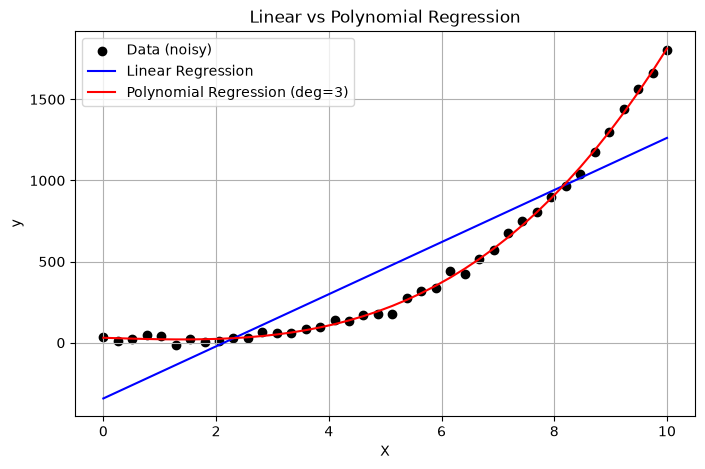

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------------
# 1) Create a non-linear dataset
# ----------------------------------
np.random.seed(0)

# feature (x) and target (y)
X = np.linspace(0, 10, 40).reshape(-1, 1)
y_true = 2 * X**3 - 2 * X**2 + X + 3        # underlying cubic function
noise = np.random.normal(scale=20, size=X.shape)
y = (y_true + noise).ravel()                 # noisy observations

# ----------------------------------
# 2) Simple linear regression
# ----------------------------------
lin_reg = LinearRegression()
lin_reg.fit(X, y)

y_lin_pred = lin_reg.predict(X)

mse_lin = mean_squared_error(y, y_lin_pred)
r2_lin = r2_score(y, y_lin_pred)

print("=== Linear Regression ===")
print("Coefficient:", lin_reg.coef_)
print("Intercept:", lin_reg.intercept_)
print("MSE:", mse_lin)
print("R^2:", r2_lin)

# ----------------------------------
# 3) Polynomial regression (degree = 3)
# ----------------------------------
poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)               # [x, x^2, x^3]

poly_reg = LinearRegression()
poly_reg.fit(X_poly, y)

y_poly_pred = poly_reg.predict(X_poly)

mse_poly = mean_squared_error(y, y_poly_pred)
r2_poly = r2_score(y, y_poly_pred)

print("\n=== Polynomial Regression (degree 3) ===")
print("Coefficients:", poly_reg.coef_)
print("Intercept:", poly_reg.intercept_)
print("MSE:", mse_poly)
print("R^2:", r2_poly)

# ----------------------------------
# 4) Plot data + both models
# ----------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="black", label="Data (noisy)")

# sort X for smooth lines
sort_idx = np.argsort(X[:, 0])
X_sorted = X[sort_idx]

y_lin_sorted = lin_reg.predict(X_sorted)
X_poly_sorted = poly.transform(X_sorted)
y_poly_sorted = poly_reg.predict(X_poly_sorted)

plt.plot(X_sorted, y_lin_sorted, color="blue", label="Linear Regression")
plt.plot(X_sorted, y_poly_sorted, color="red", label="Polynomial Regression (deg=3)")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()
